# MDPs, value functions, optimality: implementation

A finite Markov decision process (MDP) container, exact and iterative solutions of the Bellman equations,
the recycling robot and the gridworld as worked examples, all checked against exact solutions,
simulated returns and the values printed in the chapter.
The chapter's golf example is not implemented: it appears only as contour figures, with no dynamics or numbers to code.
Companion to the chapter note: [MDPs, value functions, optimality](../chapters/03b%20MDPs%2C%20value%20functions%2C%20optimality.md).

**Sections**
1. A finite MDP and its dynamics
2. Value functions of a policy
3. Optimal value functions and the recycling robot
4. The gridworld
5. Checkpoints

In [1]:
from dataclasses import dataclass
from functools import partial
from itertools import product

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.optimize import fsolve

plt.rcParams.update({"figure.figsize": (7, 4), "axes.grid": True, "axes.spines.top": False, "axes.spines.right": False})

SEED_EVAL, SEED_GRID = 1, 2
TOL = 1e-12  # sweeps stop when no value changes by more than this
HORIZON = 150  # steps per simulated trajectory; the discounted tail beyond it is below 1e-6 of a reward
N_RUNS_ROBOT, N_RUNS_GRID = 4000, 2000  # simulated trajectories per start state

HIGH, LOW = 0, 1
SEARCH, WAIT, RECHARGE = 0, 1, 2
STATES, ACTIONS = ("high", "low"), ("search", "wait", "recharge")
ROBOT = dict(alpha=0.8, beta=0.5, r_search=2.0, r_wait=1.0)
GAMMA_ROBOT = 0.9
SETTINGS = {  # each setting changes one thing in the baseline: (parameter overrides, discount)
    "baseline": ({}, GAMMA_ROBOT),
    "cheap waiting": (dict(r_wait=1.8), GAMMA_ROBOT),
    "short horizon": ({}, 0.5),
    "safe search": (dict(beta=0.9), GAMMA_ROBOT),
    "fast drain": (dict(alpha=0.2), GAMMA_ROBOT),
}

GRID_N, GAMMA_GRID = 5, 0.9
A, A_PRIME, B, B_PRIME = (0, 1), (4, 1), (0, 3), (2, 3)  # (row, column), row 0 on top
R_A, R_B, R_EDGE = 10.0, 5.0, -1.0
A_IDX = A[0] * GRID_N + A[1]
TAIL_BOUND = R_A * GAMMA_GRID**HORIZON / (1 - GAMMA_GRID)  # most a 150-step truncation can miss, since no reward exceeds R_A
BOOK_TOL = 0.05 + 1e-9  # half a unit of the printed decimal, plus slack for floating point
MOVES = {"N": (-1, 0), "S": (1, 0), "E": (0, 1), "W": (0, -1)}  # action order: north, south, east, west
BOOK_V_PI = np.array([[3.3, 8.8, 4.4, 5.3, 1.5], [1.5, 3.0, 2.3, 1.9, 0.5], [0.1, 0.7, 0.7, 0.4, -0.4],
                      [-1.0, -0.4, -0.4, -0.6, -1.2], [-1.9, -1.3, -1.2, -1.4, -2.0]])
BOOK_V_STAR = np.array([[22.0, 24.4, 22.0, 19.4, 17.5], [19.8, 22.0, 19.8, 17.8, 16.0], [17.8, 19.8, 17.8, 16.0, 14.4],
                        [16.0, 17.8, 16.0, 14.4, 13.0], [14.4, 16.0, 14.4, 13.0, 11.7]])
BOOK_PI_STAR = [["E", "NSEW", "W", "NSEW", "W"], ["NE", "N", "NW", "W", "W"]] + [["NE", "N", "NW", "NW", "NW"]] * 3

## 1. A finite MDP and its dynamics

A finite MDP is fixed by its state set, its action sets and the one-step dynamics: the probability of each
pair of next state $s'$ and reward $r$ after taking action $a$ in state $s$.

$$
p(s', r \mid s, a) = \Pr\{S_{t+1}=s',\, R_{t+1}=r \mid S_t=s,\, A_t=a\}
$$

- In both examples of this notebook the reward is fixed by the triple $(s, a, s')$, so the dynamics reduce to two arrays:
  `P[s, a, s']` $= p(s' \mid s, a)$ and `R[s, a, s']` $= r(s, a, s')$. The pair $(s', r)$ then has probability `P[s, a, s']`.
- `allowed[s, a]` marks the actions in $\mathcal{A}(s)$; disallowed actions have all-zero probabilities.
- Everything else about the environment follows from the dynamics, for example the expected reward
  $r(s,a) = \sum_{s'} p(s' \mid s, a)\, r(s, a, s')$.

The first example is the recycling robot: a robot with battery level high or low that can search for cans, wait, or (when low) recharge.
Searching from high keeps the battery high with probability $\alpha$; searching from low keeps it low with probability $\beta$
and otherwise depletes it, which costs a rescue reward of $-3$ and returns the battery to high.
The expected cans collected while searching and waiting are $r_{\text{s}}$ and $r_{\text{w}}$ (`r_search`, `r_wait`), with $r_{\text{s}} > r_{\text{w}}$.
The chapter gives no numbers for these parameters; the notebook picks `ROBOT` above.

In [2]:
@dataclass(frozen=True, eq=False)
class FiniteMDP:
    """Dynamics of a finite MDP with the reward fixed by (s, a, s'): p(s'|s,a) = P[s,a,s'], r(s,a,s') = R[s,a,s']."""

    P: np.ndarray
    R: np.ndarray
    allowed: np.ndarray

    def __post_init__(self):
        mass = self.P.sum(-1)
        assert np.allclose(mass[self.allowed], 1) and not mass[~self.allowed].any(), "probabilities must sum to 1"

    @property
    def n_states(self) -> int:
        return self.P.shape[0]

    @property
    def n_actions(self) -> int:
        return self.P.shape[1]

    def expected_reward(self) -> np.ndarray:
        """r(s, a), shape (states, actions)."""
        return (self.P * self.R).sum(-1)

    def outcomes(self, s: int, a: int) -> list[tuple[int, float, float]]:
        """All (s', r, p(s', r | s, a)) with positive probability."""
        return [(s2, self.R[s, a, s2], self.P[s, a, s2]) for s2 in np.flatnonzero(self.P[s, a])]

In [3]:
def recycling_robot(alpha: float, beta: float, r_search: float, r_wait: float) -> FiniteMDP:
    """The recycling robot's dynamics, row by row as in the book's table; the rescue reward is -3."""
    P, R = np.zeros((2, 3, 2)), np.zeros((2, 3, 2))
    allowed = np.ones((2, 3), bool)
    allowed[HIGH, RECHARGE] = False
    P[HIGH, SEARCH], R[HIGH, SEARCH] = [alpha, 1 - alpha], r_search
    P[LOW, SEARCH], R[LOW, SEARCH] = [1 - beta, beta], [-3.0, r_search]
    P[HIGH, WAIT, HIGH] = P[LOW, WAIT, LOW] = 1
    R[:, WAIT] = r_wait
    P[LOW, RECHARGE, HIGH] = 1
    return FiniteMDP(P, R, allowed)

In [4]:
robot = recycling_robot(**ROBOT)
dynamics_rows = [
    (STATES[s], STATES[s2], ACTIONS[a], robot.P[s, a, s2], robot.R[s, a, s2])
    for s in range(2) for a in range(3) if robot.allowed[s, a] for s2 in range(2)
]
print(pd.DataFrame(dynamics_rows, columns=["s", "s'", "a", "p(s'|s,a)", "r(s,a,s')"]).to_string(index=False))

r_sa = robot.expected_reward()
print("\nExpected reward r(s,a):", {(STATES[s], ACTIONS[a]): round(float(r_sa[s, a]), 3) for s in range(2) for a in range(3) if robot.allowed[s, a]})
rs, rw, beta = ROBOT["r_search"], ROBOT["r_wait"], ROBOT["beta"]
by_hand = {(HIGH, SEARCH): rs, (HIGH, WAIT): rw, (LOW, SEARCH): beta * rs - 3 * (1 - beta), (LOW, WAIT): rw, (LOW, RECHARGE): 0.0}
print("Checkpoint: r(s,a) from the dynamics equals the by-hand expectation for every allowed pair:", all(np.isclose(r_sa[k], v) for k, v in by_hand.items()))

   s   s'        a  p(s'|s,a)  r(s,a,s')
high high   search        0.8        2.0
high  low   search        0.2        2.0
high high     wait        1.0        1.0
high  low     wait        0.0        1.0
 low high   search        0.5       -3.0
 low  low   search        0.5        2.0
 low high     wait        0.0        1.0
 low  low     wait        1.0        1.0
 low high recharge        1.0        0.0
 low  low recharge        0.0        0.0

Expected reward r(s,a): {('high', 'search'): 2.0, ('high', 'wait'): 1.0, ('low', 'search'): -0.5, ('low', 'wait'): 1.0, ('low', 'recharge'): 0.0}
Checkpoint: r(s,a) from the dynamics equals the by-hand expectation for every allowed pair: True


### Reading the result

- The printed dynamics are the chapter's table for the robot: the probabilities leaving each state-action pair sum to 1 (the container asserts it), and recharging is not available when the battery is high.
- The expected rewards follow from the dynamics. Searching from high gives 2.0 whatever happens next, waiting gives 1.0, and searching from low gives $0.5 \times 2 + 0.5 \times (-3) = -0.5$: with these parameters a search at low battery loses cans on average.
- Recharging collects nothing (0.0) but moves the robot to high for sure.

## 2. Value functions of a policy

A policy $\pi(a \mid s)$ gives the probability of each action in each state (an array `pi[s, a]`).
Its state-value function $v_\pi(s)$ is the expected discounted return from $s$ when $\pi$ is followed afterwards;
its action-value function $q_\pi(s,a)$ is the same when the first action is $a$ and $\pi$ is followed after that.

$$
v_\pi(s) = \sum_a \pi(a \mid s) \sum_{s', r} p(s', r \mid s, a)\big[r + \gamma\, v_\pi(s')\big], \qquad
q_\pi(s,a) = \sum_{s', r} p(s', r \mid s, a)\big[r + \gamma \sum_{a'} \pi(a' \mid s')\, q_\pi(s', a')\big]
$$

Here $\gamma \in [0, 1)$ is the discount rate: a reward $k$ steps ahead counts $\gamma^k$ times as much as an immediate one.
The Bellman equation says a state's value is the probability-weighted average, over the action, next state and reward, of the reward plus the discounted value of the next state.
For $N$ states it is $N$ linear equations in $N$ unknowns. Two ways to solve it:

- **Linear solve**: in matrix form $v_\pi = r_\pi + \gamma P_\pi v_\pi$, where $P_\pi$ and $r_\pi$ are the transition matrix and expected reward under $\pi$, so $v_\pi = (I - \gamma P_\pi)^{-1} r_\pi$, exact up to floating-point error.
- **Iteration**: start from zero and repeat $v \leftarrow r_\pi + \gamma P_\pi v$ until nothing changes by more than a tolerance of $10^{-12}$; each sweep shrinks the largest change by at least the factor $\gamma$.

The action values follow from the state values: $q_\pi(s,a) = r(s,a) + \gamma \sum_{s'} p(s'|s,a)\, v_\pi(s')$, and $v_\pi(s) = \sum_a \pi(a|s)\, q_\pi(s,a)$.
A third check uses no model at all: simulate trajectories, compute each discounted return $G_0$ and average. The Bellman equations are verified
by plugging the values back into the sums written out over the dynamics.

Formalized here rather than stated this way in the chapter: the Bellman equation for $q_\pi$, the two relations between $v_\pi$ and $q_\pi$, the matrix form with its linear solve, and the iteration from zero.

The policy used here is the equiprobable one: every allowed action has the same probability in each state.

In [5]:
def policy_dynamics(mdp: FiniteMDP, pi: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    """Transition matrix P_pi[s, s'] and expected reward r_pi[s] under policy `pi`."""
    return np.einsum("sa,sat->st", pi, mdp.P), (pi * mdp.expected_reward()).sum(1)


def solve_v_pi(mdp: FiniteMDP, pi: np.ndarray, gamma: float) -> np.ndarray:
    """v_pi by solving the linear Bellman system."""
    P_pi, r_pi = policy_dynamics(mdp, pi)
    return np.linalg.solve(np.eye(mdp.n_states) - gamma * P_pi, r_pi)


def iterate_v_pi(mdp: FiniteMDP, pi: np.ndarray, gamma: float) -> tuple[np.ndarray, list[float]]:
    """v_pi by repeated Bellman sweeps from zero; also returns the largest change of each sweep."""
    P_pi, r_pi = policy_dynamics(mdp, pi)
    v, deltas = np.zeros(mdp.n_states), []
    while not deltas or deltas[-1] > TOL:
        new = r_pi + gamma * P_pi @ v
        deltas.append(float(np.abs(new - v).max()))
        v = new
    return v, deltas


def q_from_v(mdp: FiniteMDP, v: np.ndarray, gamma: float) -> np.ndarray:
    """Action values by one-step lookahead on `v`; nan for actions that are not allowed."""
    return np.where(mdp.allowed, mdp.expected_reward() + gamma * mdp.P @ v, np.nan)


def v_from_q(pi: np.ndarray, q: np.ndarray) -> np.ndarray:
    """State values as the policy-weighted average of action values."""
    return np.where(pi > 0, pi * q, 0.0).sum(1)

In [6]:
def residual_v_pi(mdp: FiniteMDP, pi: np.ndarray, gamma: float, v: np.ndarray) -> float:
    """Largest gap between v(s) and the Bellman right-hand side, summed explicitly over (a, s', r)."""
    rhs = [sum(pi[s, a] * sum(p * (r + gamma * v[s2]) for s2, r, p in mdp.outcomes(s, a)) for a in range(mdp.n_actions)) for s in range(mdp.n_states)]
    return float(np.abs(np.array(rhs) - v).max())


def residual_q_pi(mdp: FiniteMDP, pi: np.ndarray, gamma: float, q: np.ndarray) -> float:
    """Largest gap between q(s,a) and its Bellman right-hand side, over allowed pairs."""
    gaps = [
        abs(q[s, a] - sum(p * (r + gamma * (pi[s2] * np.nan_to_num(q[s2])).sum()) for s2, r, p in mdp.outcomes(s, a)))
        for s in range(mdp.n_states) for a in range(mdp.n_actions) if mdp.allowed[s, a]
    ]
    return max(gaps)


def sample_returns(mdp: FiniteMDP, pi: np.ndarray, gamma: float, starts: np.ndarray, rng: np.random.Generator) -> np.ndarray:
    """Discounted return of one simulated trajectory from each entry of `starts`, truncated after HORIZON steps."""
    s, G = starts.copy(), np.zeros(len(starts))
    cum_pi, cum_p = pi.cumsum(1), mdp.P.cumsum(2)
    for t in range(HORIZON):
        a = np.minimum((rng.random(len(s))[:, None] > cum_pi[s]).sum(1), mdp.n_actions - 1)
        s2 = np.minimum((rng.random(len(s))[:, None] > cum_p[s, a]).sum(1), mdp.n_states - 1)
        G += gamma**t * mdp.R[s, a, s2]
        s = s2
    return G


def mean_and_se(returns: np.ndarray, n_runs: int) -> tuple[np.ndarray, np.ndarray]:
    """Per-start-state mean return and its standard error, from returns laid out start state by start state."""
    g = returns.reshape(-1, n_runs)
    return g.mean(1), g.std(1, ddof=1) / np.sqrt(n_runs)

In [7]:
rng = np.random.default_rng(SEED_EVAL)
uniform = robot.allowed / robot.allowed.sum(1, keepdims=True)
v_solve = solve_v_pi(robot, uniform, GAMMA_ROBOT)
v_iter, deltas = iterate_v_pi(robot, uniform, GAMMA_ROBOT)
q_pi = q_from_v(robot, v_solve, GAMMA_ROBOT)
print(f"Equiprobable policy, gamma={GAMMA_ROBOT}: v_pi by linear solve {v_solve.round(4)}, by {len(deltas)} sweeps {v_iter.round(4)}")
print("q_pi(s,a):", {(STATES[s], ACTIONS[a]): round(float(q_pi[s, a]), 3) for s in range(2) for a in range(3) if robot.allowed[s, a]})
print(f"Bellman residual of v_pi: {residual_v_pi(robot, uniform, GAMMA_ROBOT, v_solve):.1e}, of q_pi: {residual_q_pi(robot, uniform, GAMMA_ROBOT, q_pi):.1e}")
print("Checkpoint: linear solve and iteration agree:", np.allclose(v_solve, v_iter, atol=1e-9))
print("Checkpoint: v_pi(s) is the pi-weighted average of q_pi(s, a):", np.allclose(v_from_q(uniform, q_pi), v_solve))

G = sample_returns(robot, uniform, GAMMA_ROBOT, np.repeat([HIGH, LOW], N_RUNS_ROBOT), rng)
mean_robot, se_robot = mean_and_se(G, N_RUNS_ROBOT)
for s in range(2):
    print(f"Simulated return from {STATES[s]}: {mean_robot[s]:.3f} +/- {se_robot[s]:.3f} (standard error) vs exact {v_solve[s]:.3f}")
print("Checkpoint: simulated means lie within 4 standard errors of v_pi:", bool((np.abs(mean_robot - v_solve) < 4 * se_robot).all()))

Equiprobable policy, gamma=0.9: v_pi by linear solve [13.125  11.0417], by 266 sweeps [13.125  11.0417]
q_pi(s,a): {('high', 'search'): 13.438, ('high', 'wait'): 12.813, ('low', 'search'): 10.375, ('low', 'wait'): 10.938, ('low', 'recharge'): 11.813}
Bellman residual of v_pi: 1.8e-15, of q_pi: 1.8e-15
Checkpoint: linear solve and iteration agree: True
Checkpoint: v_pi(s) is the pi-weighted average of q_pi(s, a): True
Simulated return from high: 13.125 +/- 0.026 (standard error) vs exact 13.125
Simulated return from low: 11.007 +/- 0.030 (standard error) vs exact 11.042
Checkpoint: simulated means lie within 4 standard errors of v_pi: True


### Reading the result

- Under the equiprobable policy the exact values are $v_\pi(\text{high}) = 13.125$ and $v_\pi(\text{low}) = 11.0417$. Solving the linear system and sweeping 266 times from zero give the same numbers, and the Bellman residual (the largest gap between a value and its right-hand side) is about $10^{-15}$, floating-point noise.
- The action values are 13.438 (search) and 12.813 (wait) at high, and 10.375 (search), 10.938 (wait) and 11.813 (recharge) at low. Each state value is the average of its action values, as the check confirms: for example $(13.438 + 12.813)/2 = 13.125$.
- The simulated mean return is 13.125 with standard error 0.026 from high (exact 13.125) and 11.007 with standard error 0.030 from low (exact 11.042). The low-battery gap of 0.035 is about 1.2 standard errors, so the sample agrees with the exact solution.
- Under this random policy, recharging is the best first action at low battery and searching the worst; the next section finds the best policy.

## 3. Optimal value functions and the recycling robot

The optimal value functions are the largest values any policy achieves in each state or state-action pair,
$v_*(s) = \max_\pi v_\pi(s)$ and $q_*(s,a) = \max_\pi q_\pi(s,a)$. They satisfy the Bellman optimality equations, which replace the policy average by a maximum:

$$
v_*(s) = \max_a \sum_{s', r} p(s', r \mid s, a)\big[r + \gamma\, v_*(s')\big], \qquad
q_*(s,a) = \sum_{s', r} p(s', r \mid s, a)\big[r + \gamma \max_{a'} q_*(s', a')\big]
$$

- These equations are nonlinear because of the maximum, so there is no matrix inverse. Repeating them as updates, starting from zero, converges to the unique solution; this iteration is formalized here, not spelled out in the chapter.
- Any policy that puts probability only on actions achieving the maximum (a *greedy* policy with respect to $v_*$) is optimal. With $q_*$ the maximizing actions are read off directly, without the dynamics.
- Truth: the recycling robot has two states and only six deterministic policies, so $v_*$ is also the pointwise maximum of $v_\pi$ over all six, computed with the linear solve (formalized here; the chapter defines $v_*$ as a maximum over all policies). For the robot's two equations,
  a general nonlinear root finder gives a third route.

The chapter's two equations for the robot are, with $h$ and $l$ for high and low,

$$
v_*(h) = \max\{\, r_{\text{s}} + \gamma[\alpha\, v_*(h) + (1-\alpha)\, v_*(l)],\; r_{\text{w}} + \gamma\, v_*(h) \,\}
$$

$$
v_*(l) = \max\{\, \beta r_{\text{s}} - 3(1-\beta) + \gamma[(1-\beta)\, v_*(h) + \beta\, v_*(l)],\; r_{\text{w}} + \gamma\, v_*(l),\; \gamma\, v_*(h) \,\}
$$

Five settings, each changing one thing in the baseline (one parameter, or the discount), show how the best action depends on it.

In [8]:
def optimal_values(mdp: FiniteMDP, gamma: float) -> tuple[np.ndarray, list[float]]:
    """v_* by iterating the Bellman optimality equation from zero; also returns the largest change of each sweep."""
    v, deltas = np.zeros(mdp.n_states), []
    while not deltas or deltas[-1] > TOL:
        new = np.nanmax(q_from_v(mdp, v, gamma), axis=1)
        deltas.append(float(np.abs(new - v).max()))
        v = new
    return v, deltas


def optimal_q(mdp: FiniteMDP, gamma: float) -> np.ndarray:
    """q_* by iterating its own Bellman optimality equation, which never uses v_*."""
    r, q, delta = mdp.expected_reward(), np.zeros((mdp.n_states, mdp.n_actions)), np.inf
    while delta > TOL:
        new = np.where(mdp.allowed, r + gamma * mdp.P @ np.nanmax(np.where(mdp.allowed, q, np.nan), axis=1), np.nan)
        delta, q = float(np.nanmax(np.abs(new - np.where(mdp.allowed, q, np.nan)))), new
    return q


def greedy_policy(q: np.ndarray, atol: float = 1e-9) -> np.ndarray:
    """Equal probability on every action whose value is within `atol` of the best in its state."""
    best = np.nanmax(q, axis=1, keepdims=True)
    ties = np.where(np.isnan(q), False, q >= best - atol)
    return ties / ties.sum(1, keepdims=True)

In [9]:
def residual_v_star(mdp: FiniteMDP, gamma: float, v: np.ndarray) -> float:
    """Largest gap between v(s) and the right-hand side of its Bellman optimality equation."""
    rhs = [max(sum(p * (r + gamma * v[s2]) for s2, r, p in mdp.outcomes(s, a)) for a in range(mdp.n_actions) if mdp.allowed[s, a]) for s in range(mdp.n_states)]
    return float(np.abs(np.array(rhs) - v).max())


def residual_q_star(mdp: FiniteMDP, gamma: float, q: np.ndarray) -> float:
    """Largest gap between q(s,a) and the right-hand side of its Bellman optimality equation."""
    best = np.nanmax(q, axis=1)
    return max(abs(q[s, a] - sum(p * (r + gamma * best[s2]) for s2, r, p in mdp.outcomes(s, a))) for s in range(mdp.n_states) for a in range(mdp.n_actions) if mdp.allowed[s, a])


def robot_equations(v: np.ndarray, *, alpha: float, beta: float, r_search: float, r_wait: float, gamma: float) -> list[float]:
    """The chapter's two Bellman optimality equations for the robot, as v minus right-hand side."""
    v_high, v_low = v
    return [
        v_high - max(r_search + gamma * (alpha * v_high + (1 - alpha) * v_low), r_wait + gamma * v_high),
        v_low - max(beta * r_search - 3 * (1 - beta) + gamma * ((1 - beta) * v_high + beta * v_low), r_wait + gamma * v_low, gamma * v_high),
    ]

In [10]:
def best_actions(q_row: np.ndarray) -> str:
    return "/".join(ACTIONS[a] for a in np.flatnonzero(q_row >= np.nanmax(q_row) - 1e-9))


settings_rows, gap_rows, v_best = [], [], {}
for name, (overrides, gamma) in SETTINGS.items():
    params = {**ROBOT, **overrides}
    mdp = recycling_robot(**params)
    v_star, _ = optimal_values(mdp, gamma)
    q_star = optimal_q(mdp, gamma)
    pi_star = greedy_policy(q_star)
    deterministic = [np.eye(3)[list(choice)] for choice in product(*[np.flatnonzero(m) for m in mdp.allowed])]
    v_brute = np.max([solve_v_pi(mdp, pi, gamma) for pi in deterministic], axis=0)
    root = fsolve(partial(robot_equations, gamma=gamma, **params), np.zeros(2), xtol=1e-13)
    gap_rows.append({
        "setting": name,
        "v* vs best of 6 policies": np.abs(v_star - v_brute).max(),
        "v* vs root finder": np.abs(v_star - root).max(),
        "residual of v*": residual_v_star(mdp, gamma, v_star),
        "residual of q*": residual_q_star(mdp, gamma, q_star),
        "v_pi(greedy) vs v*": np.abs(solve_v_pi(mdp, pi_star, gamma) - v_star).max(),
        "greedy sets, q* vs v* lookahead (mismatches)": int((greedy_policy(q_from_v(mdp, v_star, gamma)) != pi_star).sum()),
    })
    v_best[name] = (v_star, v_brute, best_actions(q_star[HIGH]), best_actions(q_star[LOW]))
    settings_rows.append({"setting": name, **params, "gamma": gamma, "v*(high)": v_star[HIGH], "v*(low)": v_star[LOW], "best at high": v_best[name][2], "best at low": v_best[name][3]})
print(pd.DataFrame(settings_rows).round(3).to_string(index=False))
gaps = pd.DataFrame(gap_rows).set_index("setting")
print("\nDisagreement between routes (iterations stop at changes below 1e-12, so gaps near 1e-11 are that stopping rule, not method error):")
print(gaps.to_string(float_format=lambda x: f"{x:.1e}"))
exact_gaps = gaps.drop(columns=gaps.columns[-1])
print(f"Checkpoint: largest gap {exact_gaps.to_numpy().max():.1e} (below 1e-10) and no greedy-set mismatch:", bool(exact_gaps.to_numpy().max() < 1e-10 and gaps.iloc[:, -1].sum() == 0))

base = recycling_robot(**ROBOT)
v_base, _ = optimal_values(base, GAMMA_ROBOT)
q_base = optimal_q(base, GAMMA_ROBOT)
print("\nBaseline q_*(s,a):", {(STATES[s], ACTIONS[a]): round(float(q_base[s, a]), 3) for s in range(2) for a in range(3) if base.allowed[s, a]})
print("Baseline v_pi of the equiprobable policy:", solve_v_pi(base, uniform, GAMMA_ROBOT).round(3), "versus v_*:", v_base.round(3))
print("Checkpoint: v_* is at least v_pi of the equiprobable policy in both states:", bool((v_base >= solve_v_pi(base, uniform, GAMMA_ROBOT) - 1e-12).all()))

      setting  alpha  beta  r_search  r_wait  gamma  v*(high)  v*(low) best at high best at low
     baseline    0.8   0.5       2.0     1.0    0.9    16.949   15.254       search    recharge
cheap waiting    0.8   0.5       2.0     1.8    0.9    18.714   18.000       search        wait
short horizon    0.8   0.5       2.0     1.0    0.5     3.667    2.000       search        wait
  safe search    0.8   0.9       2.0     1.0    0.9    17.568   16.216       search      search
   fast drain    0.2   0.5       2.0     1.0    0.9    11.628   10.465       search    recharge

Disagreement between routes (iterations stop at changes below 1e-12, so gaps near 1e-11 are that stopping rule, not method error):
               v* vs best of 6 policies  v* vs root finder  residual of v*  residual of q*  v_pi(greedy) vs v*  greedy sets, q* vs v* lookahead (mismatches)
setting                                                                                                                                

### Reading the result

- In the baseline the robot searches when high and recharges when low: at low battery $q_*$ is 13.992 for search, 14.729 for wait and 15.254 for recharge, and at high battery 16.949 for search against 16.254 for wait.
- Each other setting changes one thing in the baseline. Raising $r_{\text{w}}$ from 1.0 to 1.8 makes waiting best at low battery ($v_*$ rises to 18.714 and 18.000); lowering $\gamma$ from 0.9 to 0.5 also makes waiting best at low battery, consistent with recharging paying nothing now and its benefit arriving later; raising $\beta$ from 0.5 to 0.9 makes searching best at low battery too; lowering $\alpha$ from 0.8 to 0.2 changes no best action but cuts $v_*$ to 11.628 and 10.465. In all five settings searching is best at high battery. These are effects of single changes around one baseline, not general rules.
- The routes agree. The table lists each gap separately: iteration against the best of all 6 deterministic policies, against the root finder on the chapter's two equations, the two Bellman optimality residuals, the value of the greedy policy against $v_*$, and the mismatch count between the greedy action sets read from $q_*$ and from a one-step lookahead on $v_*$ (0 in every setting). The gaps are at most $8.9 \times 10^{-12}$; the sweeps stop when no value changes by more than $10^{-12}$, so that scale is the stopping rule and not a difference between methods.
- In the baseline $v_* = (16.949, 15.254)$ against $(13.125, 11.042)$ for the equiprobable policy, so the optimal policy is better in both states, as it must be.

## 4. The gridworld

A 5 by 5 grid; each cell is a state and the four actions (north, south, east, west) move the agent one cell deterministically.

- Moves that would leave the grid keep the agent in place and give reward $-1$; every other move gives 0.
- From the special cell A every action gives $+10$ and moves the agent to A'; from B every action gives $+5$ and moves it to B'.
- The discount rate is $\gamma = 0.9$ and the first policy is equiprobable: each action has probability 1/4 in every cell.

The task is continuing, so every value is finite only because of discounting. The notebook computes $v_\pi$ for the equiprobable policy by linear solve,
then $v_*$ and the optimal policy, and compares both with the values printed in the chapter (printed to one decimal place, so a cell agrees when the exact value is within 0.05 of the printed one, plus $10^{-9}$ for floating-point error).
Finally it simulates trajectories from every cell under each policy.

In [11]:
def index(cell: tuple[int, int]) -> int:
    return cell[0] * GRID_N + cell[1]


def gridworld() -> FiniteMDP:
    """The 5x5 gridworld with special cells A and B; state index = row * GRID_N + column."""
    n = GRID_N * GRID_N
    P, R = np.zeros((n, 4, n)), np.zeros((n, 4, n))
    for s in range(n):
        row, col = divmod(s, GRID_N)
        for a, (dr, dc) in enumerate(MOVES.values()):
            if s == index(A):
                s2, r = index(A_PRIME), R_A
            elif s == index(B):
                s2, r = index(B_PRIME), R_B
            elif 0 <= row + dr < GRID_N and 0 <= col + dc < GRID_N:
                s2, r = index((row + dr, col + dc)), 0.0
            else:
                s2, r = s, R_EDGE
            P[s, a, s2], R[s, a, s2] = 1, r
    return FiniteMDP(P, R, np.ones((n, 4), bool))

In [12]:
def show_values(ax, grid: np.ndarray, title: str) -> None:
    ax.imshow(grid, cmap="Blues", alpha=0.6)
    for (row, col), val in np.ndenumerate(grid):
        ax.text(col, row, f"{val:.1f}", ha="center", va="center")
    for label, (row, col) in {"A": A, "A'": A_PRIME, "B": B, "B'": B_PRIME}.items():
        ax.text(col - 0.4, row - 0.35, label, fontsize=8, color="crimson", ha="left", va="center")
    ax.set(title=title, xticks=[], yticks=[])
    ax.grid(False)
    ax.spines[:].set_visible(False)


def show_policy(ax, pi: np.ndarray, title: str) -> None:
    ax.imshow(np.zeros((GRID_N, GRID_N)), cmap="Greys", vmin=0, vmax=1)
    for s, a in zip(*np.nonzero(pi > 0)):
        row, col = divmod(s, GRID_N)
        dr, dc = list(MOVES.values())[a]
        ax.annotate("", xy=(col + 0.38 * dc, row + 0.38 * dr), xytext=(col, row), arrowprops=dict(arrowstyle="->", lw=1.5))
    ax.set(title=title, xticks=[], yticks=[])
    ax.grid(False)
    ax.spines[:].set_visible(False)

v_pi by linear solve vs 221 sweeps: largest difference 8.7e-12; Bellman residual 4.4e-16
v_* after 286 sweeps; Bellman optimality residual 8.2e-13 (v_*), 8.2e-13 (q_*)
v_pi: A 8.789, B 5.322; book prints 8.8 and 5.3. v_*: A 24.419 (book 24.4)
Largest |exact - printed| over 25 cells: v_pi 0.0499, v_* 0.0225 (allowed 0.05)
Checkpoint: every cell of v_pi and of v_* is within the printed precision of the book's grids: True
Checkpoint: every sweep's largest change stays below 10 * gamma^(k-1): True
Checkpoint: the greedy action sets match the book's arrows in all cells: True
Centre cell from the printed neighbours: 0.675 (exact 0.673, printed 0.7)


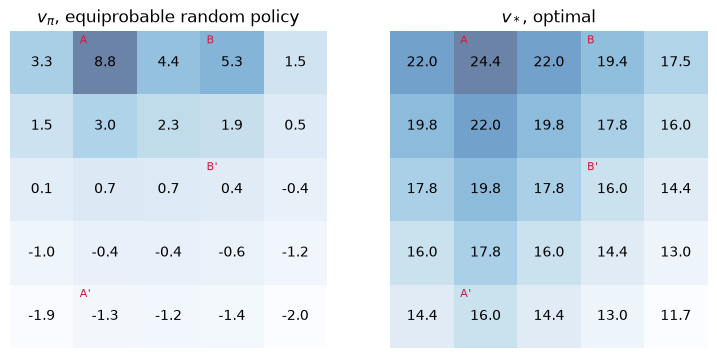

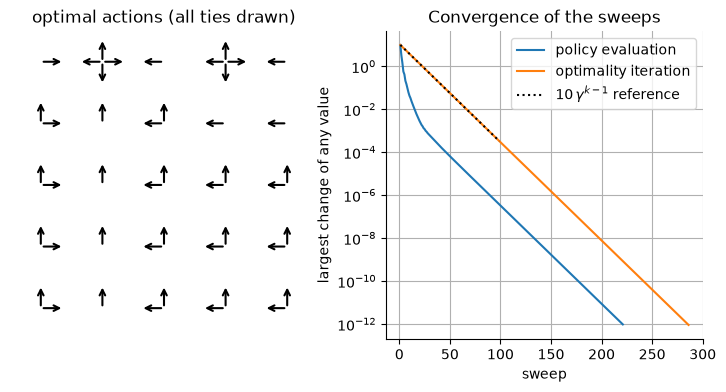

In [13]:
grid = gridworld()
random_pi = np.full((25, 4), 0.25)
v_pi, deltas_pi = iterate_v_pi(grid, random_pi, GAMMA_GRID)
v_pi_solve = solve_v_pi(grid, random_pi, GAMMA_GRID)
q_g = optimal_q(grid, GAMMA_GRID)
v_g, deltas_star = optimal_values(grid, GAMMA_GRID)
pi_g = greedy_policy(q_g)
v_pi_grid, v_star_grid = v_pi_solve.reshape(5, 5), v_g.reshape(5, 5)

print(f"v_pi by linear solve vs {len(deltas_pi)} sweeps: largest difference {np.abs(v_pi - v_pi_solve).max():.1e}; Bellman residual {residual_v_pi(grid, random_pi, GAMMA_GRID, v_pi_solve):.1e}")
print(f"v_* after {len(deltas_star)} sweeps; Bellman optimality residual {residual_v_star(grid, GAMMA_GRID, v_g):.1e} (v_*), {residual_q_star(grid, GAMMA_GRID, q_g):.1e} (q_*)")
print(f"v_pi: A {v_pi_grid[A]:.3f}, B {v_pi_grid[B]:.3f}; book prints 8.8 and 5.3. v_*: A {v_star_grid[A]:.3f} (book 24.4)")
gap_pi, gap_star = np.abs(v_pi_grid - BOOK_V_PI).max(), np.abs(v_star_grid - BOOK_V_STAR).max()
print(f"Largest |exact - printed| over 25 cells: v_pi {gap_pi:.4f}, v_* {gap_star:.4f} (allowed {BOOK_TOL:.2f})")
print("Checkpoint: every cell of v_pi and of v_* is within the printed precision of the book's grids:", bool(gap_pi <= BOOK_TOL and gap_star <= BOOK_TOL))
ref = 10.0 * GAMMA_GRID ** np.arange(max(len(deltas_pi), len(deltas_star)))
print("Checkpoint: every sweep's largest change stays below 10 * gamma^(k-1):", bool((np.array(deltas_pi) <= ref[: len(deltas_pi)] + 1e-12).all() and (np.array(deltas_star) <= ref[: len(deltas_star)] + 1e-12).all()))
sets = [[("".join(k for k, p in zip(MOVES, pi_g[r * 5 + c]) if p > 0)) for c in range(5)] for r in range(5)]
same_sets = [[set(x) == set(y) for x, y in zip(a, b)] for a, b in zip(sets, BOOK_PI_STAR)]
print("Checkpoint: the greedy action sets match the book's arrows in all cells:", all(map(all, same_sets)))
centre = 0.25 * GAMMA_GRID * (BOOK_V_PI[1, 2] + BOOK_V_PI[3, 2] + BOOK_V_PI[2, 1] + BOOK_V_PI[2, 3])
print(f"Centre cell from the printed neighbours: {centre:.3f} (exact {v_pi_grid[2, 2]:.3f}, printed {BOOK_V_PI[2, 2]})")

fig, axes = plt.subplots(1, 2, figsize=(9, 4.2))
show_values(axes[0], v_pi_grid, "$v_\\pi$, equiprobable random policy")
show_values(axes[1], v_star_grid, "$v_*$, optimal")
plt.show()
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
show_policy(axes[0], pi_g, "optimal actions (all ties drawn)")
for name, d in {"policy evaluation": deltas_pi, "optimality iteration": deltas_star}.items():
    axes[1].semilogy(range(1, len(d) + 1), d, label=name)
axes[1].semilogy(range(1, 100), ref[:99], "k:", label="$10\\,\\gamma^{k-1}$ reference")
axes[1].set(xlabel="sweep", ylabel="largest change of any value", title="Convergence of the sweeps")
axes[1].legend()
plt.show()

In [14]:
rng = np.random.default_rng(SEED_GRID)
starts = np.repeat(np.arange(25), N_RUNS_GRID)
sim = {}
for name, pi, truth in [("equiprobable", random_pi, v_pi_solve), ("optimal", pi_g, v_g)]:
    mean, se = mean_and_se(sample_returns(grid, pi, GAMMA_GRID, starts, rng), N_RUNS_GRID)
    ok = bool((np.abs(mean - truth) <= 4 * se + TAIL_BOUND).all())
    sim[name] = dict(gap=np.abs(mean - truth).max(), ok=ok, at_A=mean[A_IDX], se_A=se[A_IDX], exact_A=truth[A_IDX], se_max=se.max())
    print(f"{name}: largest |simulated mean - exact| over 25 cells {sim[name]['gap']:.3f}, largest standard error {sim[name]['se_max']:.3f}; at A: {sim[name]['at_A']:.2f} +/- {sim[name]['se_A']:.2f} vs exact {sim[name]['exact_A']:.2f}")
print(f"Checkpoint: every cell's simulated mean is within 4 standard errors plus the truncation bound {TAIL_BOUND:.1e}:", all(s["ok"] for s in sim.values()))

equiprobable: largest |simulated mean - exact| over 25 cells 0.142, largest standard error 0.094; at A: 8.75 +/- 0.04 vs exact 8.79
optimal: largest |simulated mean - exact| over 25 cells 0.000, largest standard error 0.000; at A: 24.42 +/- 0.00 vs exact 24.42
Checkpoint: every cell's simulated mean is within 4 standard errors plus the truncation bound 1.4e-05: True


### Reading the result

- The linear solve gives $v_\pi(A) = 8.789$ and $v_\pi(B) = 5.322$, close to the chapter's 8.8 and 5.3; $v_*(A) = 24.419$ against 24.4. In all 25 cells the exact values are within the printed precision of the chapter's grids: the largest gap is 0.0499 for $v_\pi$ (the limit is 0.05) and 0.0225 for $v_*$. Neither disagrees with the chapter.
- A is worth less than its reward of 10 under the random policy, because A' sits on the bottom edge where the policy often bumps the wall. B is worth more than its 5 because B' has a positive value (0.4): from B' the random walk can stumble back onto A or B, which more than offsets the penalty for later hitting an edge. The cell above B' (1.9) lies next to B. Both effects are visible in the left grid, along with the negative values near the bottom edge.
- The greedy action sets from $q_*$ agree with the chapter's arrows in every cell (the arrows in the left panel of the second figure): all four actions are optimal at A and B (their reward and destination do not depend on the action), and several cells have two optimal actions, such as north or east in the left column.
- The centre cell from the printed neighbour values is $0.25 \times 0.9 \times (2.3 + 0.4 - 0.4 + 0.7) = 0.675$; the exact value is 0.673.
- The right plot shows the sweeps converging geometrically, below the dotted reference $10\,\gamma^{k-1}$ (the first change is 10, the largest reward) at every sweep. Iterative policy evaluation reaches changes below $10^{-12}$ after 221 sweeps and the optimality iteration after 286, hugging the reference line. The linear solve and the iteration differ by $8.7 \times 10^{-12}$, again the stopping scale. Bellman residuals are $4.4 \times 10^{-16}$ for $v_\pi$ and $8.2 \times 10^{-13}$ for $v_*$ and $q_*$.
- Simulation under the equiprobable policy: the largest gap between a cell's simulated mean and its exact value is 0.142, with a largest standard error of 0.094, and every cell is within 4 standard errors plus the truncation bound of $1.4 \times 10^{-5}$ (the most that cutting trajectories at 150 steps can miss); at A the mean is 8.75 with standard error 0.04 against 8.79.
- Under the optimal policy every trajectory from a cell earns the same return (deterministic moves, and tied actions lead to equal returns), so the standard error is zero to the printed precision. Each cell's 2000 runs are therefore one trajectory repeated, not 2000 independent pieces of evidence: that check only confirms the exact value to within the truncation bound. At A it gives 24.42.

## 5. Checkpoints

In [15]:
low_best = {name: v[3] for name, v in v_best.items()}
checks = [
    ("robot: linear solve and iteration give the same v_pi", np.allclose(v_solve, v_iter, atol=1e-9)),
    ("robot: Bellman residuals of v_pi and q_pi vanish", residual_v_pi(robot, uniform, GAMMA_ROBOT, v_solve) < 1e-10 and residual_q_pi(robot, uniform, GAMMA_ROBOT, q_pi) < 1e-10),
    ("robot: all routes to v_*, q_* and the optimal policy agree in all five settings", bool(exact_gaps.to_numpy().max() < 1e-10 and gaps.iloc[:, -1].sum() == 0)),
    ("robot: search is the best action at high battery in all five settings", all(v[2] == "search" for v in v_best.values())),
    ("robot: at low battery, recharge (baseline, fast drain), wait (cheap waiting, short horizon), search (safe search)",
     [low_best[k] for k in SETTINGS] == ["recharge", "wait", "wait", "search", "recharge"]),
    ("robot: simulated returns are within 4 standard errors of v_pi", bool((np.abs(mean_robot - v_solve) < 4 * se_robot).all())),
    ("gridworld: v_pi and v_* are within the printed precision of the book's grids", bool(gap_pi <= BOOK_TOL and gap_star <= BOOK_TOL)),
    ("gridworld: the optimal action sets match the book's arrows", all(map(all, same_sets))),
    ("gridworld: Bellman residuals vanish", max(residual_v_pi(grid, random_pi, GAMMA_GRID, v_pi_solve), residual_v_star(grid, GAMMA_GRID, v_g), residual_q_star(grid, GAMMA_GRID, q_g)) < 1e-10),
    ("gridworld: v_* is at least v_pi in every cell", bool((v_g >= v_pi_solve).all())),
    ("gridworld: simulated returns are within 4 standard errors plus the truncation bound, both policies", all(s["ok"] for s in sim.values())),
]
for claim, ok in checks:
    print(("PASS " if ok else "FAIL ") + claim)
assert all(ok for _, ok in checks)

summary = [
    ("robot v_pi(high), simulated", mean_robot[HIGH], v_solve[HIGH], "exact"),
    ("robot v_*(high), baseline, iteration", v_best["baseline"][0][HIGH], v_best["baseline"][1][HIGH], "exact (best of 6)"),
    ("gridworld v_pi(A), linear solve", v_pi_grid[A], 8.8, "book (rounded)"),
    ("gridworld v_pi(B), linear solve", v_pi_grid[B], 5.3, "book (rounded)"),
    ("gridworld v_*(A), optimality iteration", v_star_grid[A], 24.4, "book (rounded)"),
    ("gridworld v_pi(A), simulated", sim["equiprobable"]["at_A"], v_pi_solve[A_IDX], "exact"),
    ("gridworld v_*(A), simulated", sim["optimal"]["at_A"], v_g[A_IDX], "exact"),
]
print(f"\n{'quantity':<42}{'computed':>10}{'reference':>11}  source")
for name, got, want, source in summary:
    print(f"{name:<42}{got:>10.3f}{want:>11.3f}  {source}")

PASS robot: linear solve and iteration give the same v_pi
PASS robot: Bellman residuals of v_pi and q_pi vanish
PASS robot: all routes to v_*, q_* and the optimal policy agree in all five settings
PASS robot: search is the best action at high battery in all five settings
PASS robot: at low battery, recharge (baseline, fast drain), wait (cheap waiting, short horizon), search (safe search)
PASS robot: simulated returns are within 4 standard errors of v_pi
PASS gridworld: v_pi and v_* are within the printed precision of the book's grids
PASS gridworld: the optimal action sets match the book's arrows
PASS gridworld: Bellman residuals vanish
PASS gridworld: v_* is at least v_pi in every cell
PASS gridworld: simulated returns are within 4 standard errors plus the truncation bound, both policies

quantity                                    computed  reference  source
robot v_pi(high), simulated                   13.125     13.125  exact
robot v_*(high), baseline, iteration          16.949    